In [2]:
import pandas as pd
from datetime import datetime, timedelta
import matplotlib.pyplot as plt


# Read the CSV file into a pandas DataFrame with correct delimiter
df = pd.read_csv('..\\data\Turkuparkkihub_parkings_anon.csv', delimiter=';')
# Convert 'time_start' and 'time_end' columns to datetime objects with specified format
df['time_start'] = pd.to_datetime(df['time_start'], format='%d/%m/%Y %H.%M')
df['time_end'] = pd.to_datetime(df['time_end'], format='%d/%m/%Y %H.%M')

# Filter the DataFrame to cover the specified time period
start_date = datetime(2021, 10, 11)
end_date = datetime(2022, 1, 15)
df_filtered = df[(df['time_start'] >= start_date) & (df['time_end'] <= end_date)]


<>:7: SyntaxWarning: invalid escape sequence '\T'
<>:7: SyntaxWarning: invalid escape sequence '\T'
C:\Users\Viktor\AppData\Local\Temp\ipykernel_19924\1421914282.py:7: SyntaxWarning: invalid escape sequence '\T'
  df = pd.read_csv('..\\data\Turkuparkkihub_parkings_anon.csv', delimiter=';')


Number of values for '2aa56fb6-ae54-48c9-b4d1-a707752579b4': 23325
Number of values for other operator IDs: 433822


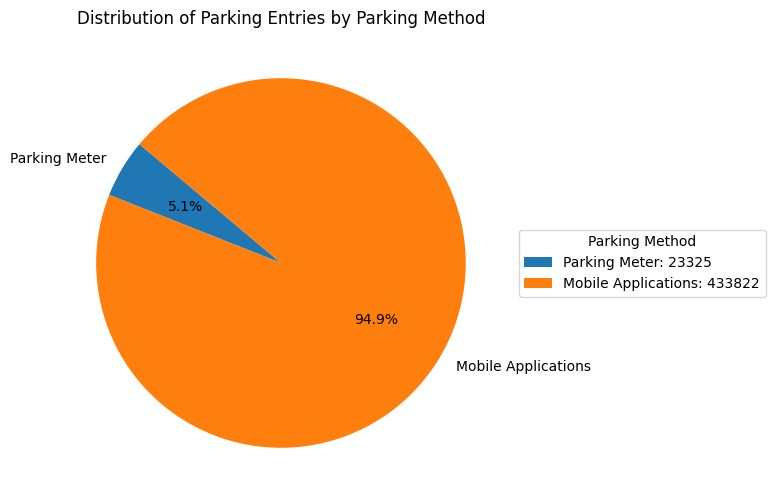

: 

In [ ]:
# Count the number of occurrences for each 'operator_id'
operator_counts = df_filtered['operator_id'].value_counts(dropna=False)

# Separate the count for '2aa56fb6-ae54-48c9-b4d1-a707752579b4' and the rest
parking_meter_count = operator_counts.get('2aa56fb6-ae54-48c9-b4d1-a707752579b4', 0)
other_operators_count = operator_counts.sum() - parking_meter_count

# Print the results
print(f"Number of values for '2aa56fb6-ae54-48c9-b4d1-a707752579b4': {parking_meter_count}")
print(f"Number of values for other operator IDs: {other_operators_count}")


# Plot the results as a pie chart with a legend
labels = ['Parking Meter', 'Mobile Applications']
counts = [parking_meter_count, other_operators_count]

plt.figure(figsize=(8, 6))
plt.pie(counts, labels=labels, autopct='%1.1f%%', startangle=140)
plt.title('Distribution of Parking Entries by Parking Method', loc='center')
plt.legend([f'Parking Meter: {parking_meter_count}', f'Mobile Applications: {other_operators_count}'], title="Parking Method", loc="center left", bbox_to_anchor=(1, 0, 0.5, 1))
plt.show()